In [ ]:
!pip install statsbombpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [statsbombpy]


In [ ]:
from statsbombpy import sb
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings('ignore', category=UserWarning)

matches = sb.matches(competition_id=55, season_id=43)
match_ids = matches['match_id'].tolist()
all_shots_data = []

for match_id in match_ids:
    print(f"Processing match {match_id}...")
    events = sb.events(match_id=match_id)
    if 'play_pattern' in events.columns:
        shots = events[(events['type'] == 'Shot') & (events['play_pattern'] == 'Regular Play')]
    else:
        continue

    try:
        frames = sb.frames(match_id=match_id, fmt='dataframe')
    except Exception:
        continue

    event_col = 'id' if 'id' in frames.columns else 'event_uuid'

    for _, shot in shots.iterrows():
        event_id = shot['id']

        if event_id in frames[event_col].values:
            frame_data = frames[frames[event_col] == event_id]
            shot_loc = np.array(shot['location'])
            goal_loc = np.array([120, 40])
            distance_to_goal = np.linalg.norm(shot_loc - goal_loc)

            defenders_5m = 0
            for _, player in frame_data.iterrows():
                if not player['teammate']:
                    player_loc = np.array(player['location'])
                    if np.linalg.norm(player_loc - shot_loc) <= 5.0:
                        defenders_5m += 1

            xg_value = shot.get('shot_statsbomb_xg', np.nan)
            first_touch = 1 if shot.get('shot_first_time') == True else 0

            all_shots_data.append({
                'event_id': event_id,
                'team': shot['team'],
                'distance_goal': round(distance_to_goal, 2),
                'defenders_5m': defenders_5m,
                'first_touch': first_touch,
                'shot_xg': xg_value
            })

df = pd.DataFrame(all_shots_data).dropna(subset=['shot_xg'])
df.to_csv('statsbomb_360_shots_xg.csv', index=False)
print(f"Extraction complete. Total shots processed: {len(df)}")
print(df.head())

Processing match 3788758...
Processing match 3788773...
Processing match 3788765...
Processing match 3788761...
Processing match 3788760...
Processing match 3795108...
Processing match 3794687...
Processing match 3794690...
Processing match 3794685...
Processing match 3794692...
Processing match 3794689...
Processing match 3795107...
Processing match 3795187...
Processing match 3795220...
Processing match 3794686...
Processing match 3788763...
Processing match 3795506...
Processing match 3788769...
Processing match 3788766...
Processing match 3788764...
Processing match 3788755...
Processing match 3788754...
Processing match 3788762...
Processing match 3788747...
Processing match 3788741...
Processing match 3795109...
Processing match 3788770...
Processing match 3794688...
Processing match 3788774...
Processing match 3788771...
Processing match 3788772...
Processing match 3788768...
Processing match 3788767...
Processing match 3788753...
Processing match 3788759...
Processing match 378

In [ ]:
import pandas as pd
import scipy.stats as stats
import numpy as np

df = pd.read_csv('statsbomb_360_shots_xg.csv')

# TEST 1 (P1): Shot quality (xG) in crowded vs open boxes
df_comp = df[(df['distance_goal'] >= 10.0) & (df['distance_goal'] <= 18.0)]

threshold_crowded = df_comp['defenders_5m'].quantile(0.66)
threshold_open = df_comp['defenders_5m'].quantile(0.33)

group_D = df_comp[df_comp['defenders_5m'] >= threshold_crowded]['shot_xg']
group_S = df_comp[df_comp['defenders_5m'] <= threshold_open]['shot_xg']

t_stat_1, p_val_1 = stats.ttest_ind(group_D, group_S, equal_var=False, alternative='less')
mean_diff_1 = group_D.mean() - group_S.mean()

se_D = group_D.std() / np.sqrt(len(group_D))
se_S = group_S.std() / np.sqrt(len(group_S))
se_diff_1 = np.sqrt(se_D**2 + se_S**2)
df_welch_1 = (se_D**2 + se_S**2)**2 / ((se_D**4 / (len(group_D)-1)) + (se_S**4 / (len(group_S)-1)))
margin_1 = stats.t.ppf(0.975, df_welch_1) * se_diff_1

print("--- Test 1 (P1): Crowded vs Open ---")
print(f"Mean xG Crowded: {group_D.mean():.3f} (n={len(group_D)}) | Mean xG Open: {group_S.mean():.3f} (n={len(group_S)})")
print(f"Estimate (Difference): {mean_diff_1:.3f}")
print(f"95% CI: [{mean_diff_1 - margin_1:.3f}, {mean_diff_1 + margin_1:.3f}]")
print(f"t-statistic: {t_stat_1:.2f} (d.f. = {df_welch_1:.0f})")
print(f"p-value: {p_val_1:.4f}\n")

# TEST 2 (P2): First-touch vs delayed shots in crowded boxes

df_crowded = df[df['defenders_5m'] >= df['defenders_5m'].quantile(0.66)]

group_first = df_crowded[df_crowded['first_touch'] == 1]['shot_xg']
group_delayed = df_crowded[df_crowded['first_touch'] == 0]['shot_xg']

t_stat_2, p_val_2 = stats.ttest_ind(group_first, group_delayed, equal_var=False, alternative='greater')
mean_diff_2 = group_first.mean() - group_delayed.mean()

se_F = group_first.std() / np.sqrt(len(group_first))
se_Del = group_delayed.std() / np.sqrt(len(group_delayed))
se_diff_2 = np.sqrt(se_F**2 + se_Del**2)
df_welch_2 = (se_F**2 + se_Del**2)**2 / ((se_F**4 / (len(group_first)-1)) + (se_Del**4 / (len(group_delayed)-1)))
margin_2 = stats.t.ppf(0.975, df_welch_2) * se_diff_2

print("--- Test 2 (P2): First-touch vs Delayed (Crowded) ---")
print(f"Mean xG First-touch: {group_first.mean():.3f} (n={len(group_first)}) | Mean xG Delayed: {group_delayed.mean():.3f} (n={len(group_delayed)})")
print(f"Estimate (Difference): {mean_diff_2:.3f}")
print(f"95% CI: [{mean_diff_2 - margin_2:.3f}, {mean_diff_2 + margin_2:.3f}]")
print(f"t-statistic: {t_stat_2:.2f} (d.f. = {df_welch_2:.0f})")
print(f"p-value: {p_val_2:.4f}")

--- Test 1 (P1): Crowded vs Open ---
Mean xG Crowded: 0.106 (n=78) | Mean xG Open: 0.125 (n=53)
Estimate (Difference): -0.019
95% CI: [-0.046, 0.007]
t-statistic: -1.44 (d.f. = 114)
p-value: 0.0767

--- Test 2 (P2): First-touch vs Delayed (Crowded) ---
Mean xG First-touch: 0.177 (n=51) | Mean xG Delayed: 0.090 (n=157)
Estimate (Difference): 0.087
95% CI: [0.037, 0.138]
t-statistic: 3.47 (d.f. = 62)
p-value: 0.0005


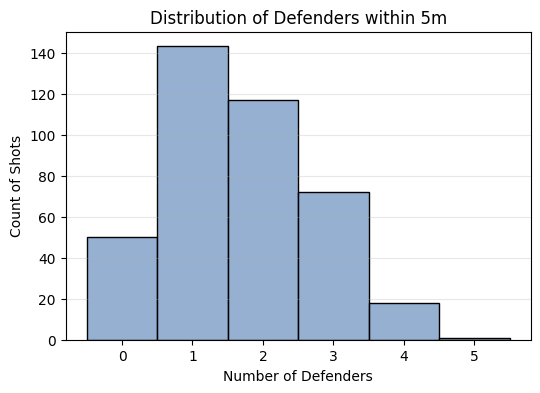

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

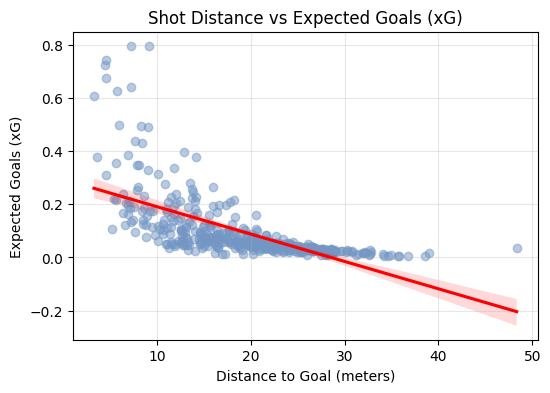

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

--- USE THESE VALUES TO UPDATE SECTION 4 ---
Density Skewness: 0.34
Shots with 4+ defenders: 4.7%
Top team volume: Denmark (40 shots)
First-touch overall xG: 0.138 | Delayed overall xG: 0.077


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

df = pd.read_csv('statsbomb_360_shots_xg.csv')

plt.figure(figsize=(6, 4))
sns.histplot(df['defenders_5m'], discrete=True, color='#7396C4')
plt.title('Distribution of Defenders within 5m')
plt.xlabel('Number of Defenders')
plt.ylabel('Count of Shots')
plt.grid(axis='y', alpha=0.3)
plt.savefig('fig_density.pdf', bbox_inches='tight')
plt.show()
files.download('fig_density.pdf')

plt.figure(figsize=(6, 4))
sns.regplot(data=df, x='distance_goal', y='shot_xg', scatter_kws={'alpha':0.5, 'color':'#7396C4'}, line_kws={'color':'red'})
plt.title('Shot Distance vs Expected Goals (xG)')
plt.xlabel('Distance to Goal (meters)')
plt.ylabel('Expected Goals (xG)')
plt.grid(alpha=0.3)
plt.savefig('fig_distance.pdf', bbox_inches='tight')
plt.show()
files.download('fig_distance.pdf')

skewness = df['defenders_5m'].skew()
pct_4_or_more = (df['defenders_5m'] >= 4).mean() * 100
top_team = df['team'].value_counts().index[0]
top_team_shots = df['team'].value_counts().iloc[0]

first_touch_xg = df[df['first_touch'] == 1]['shot_xg'].mean()
delayed_xg = df[df['first_touch'] == 0]['shot_xg'].mean()

print("--- USE THESE VALUES TO UPDATE SECTION 4 ---")
print(f"Density Skewness: {skewness:.2f}")
print(f"Shots with 4+ defenders: {pct_4_or_more:.1f}%")
print(f"Top team volume: {top_team} ({top_team_shots} shots)")
print(f"First-touch overall xG: {first_touch_xg:.3f} | Delayed overall xG: {delayed_xg:.3f}")